In [1]:
# """
# Train a ResNet-50 from scratch (randomly initialized, NOT pretrained) on
# Imagenette, where image paths and labels come from a CSV file in /Data
# instead of a folder-per-class structure.

# Uses ONLY `torch` + `torchvision` (+ Python's built-in `csv` module) — no
# Hugging Face libraries at all.

# EXPECTED CSV FORMAT
# --------------------
# /Data/<something>.csv, with:
#   - column 1: image path (assumed relative to /Data, e.g. "train/123.jpg")
#   - column 2: label (a string class name, e.g. "cat")

#     path,label
#     train/n01440764/img1.jpeg,tench
#     train/n01440764/img2.jpeg,tench
#     val/n02979186/img1.jpeg,cassette_player
#     ...

# ASSUMPTIONS (change these if your CSV differs):
#   - The CSV has a header row (set HAS_HEADER = False below if not).
#   - There's no separate train/val column, so this script creates its own
#     random train/validation split from the CSV rows.
#   - Paths in the CSV are relative to /Data. If they're already absolute,
#     the code below still works unchanged (os.path.join handles both).

In [2]:
import csv
import os
import random
 
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, models
from PIL import Image
from tqdm import tqdm   # progress bar for the training loop

In [3]:
%cd ..


%pwd

/home/geoff


'/home/geoff'

In [6]:
# ---------------------------------------------------------------------------
# 0. CONFIG — adjust these to match your CSV
# ---------------------------------------------------------------------------

DATA_DIR = "/home/geoff/Uni/imagenette2/imagenette2"
CSV_PATH = "/home/geoff/Uni/imagenette2/imagenette2/noisy_imagenette.csv"   # <-- change to your actual CSV filename
HAS_HEADER = True
VAL_FRACTION = 0.2              # 20% of rows held out for validation
RANDOM_SEED = 42

In [7]:
# ---------------------------------------------------------------------------
# 1. READ THE CSV AND BUILD (path, label) PAIRS
# ---------------------------------------------------------------------------
def load_csv_rows(csv_path, has_header):
    """Read the CSV and return a list of (image_path, label_str) tuples."""
    rows = []
    with open(csv_path, newline="") as f:
        reader = csv.reader(f)
        if has_header:
            next(reader)  # skip header row
        for row in reader:
            image_path, label = row[0], row[1]
            rows.append((image_path, label))
    return rows


all_rows = load_csv_rows(CSV_PATH, HAS_HEADER)

# Build a sorted list of unique class names, then a name -> integer index
# mapping (models need integer labels, not strings).
class_names = sorted({label for _, label in all_rows})
label_to_index = {name: i for i, name in enumerate(class_names)}
num_labels = len(class_names)
print(f"Found {num_labels} classes: {class_names}")

# Shuffle deterministically, then split into train/val since the CSV
# itself doesn't mark a split.
random.seed(RANDOM_SEED)
random.shuffle(all_rows)

split_index = int(len(all_rows) * (1 - VAL_FRACTION))
train_rows = all_rows[:split_index]
val_rows = all_rows[split_index:]
print(f"Train rows: {len(train_rows)} | Val rows: {len(val_rows)}")



Found 10 classes: ['n01440764', 'n02102040', 'n02979186', 'n03000684', 'n03028079', 'n03394916', 'n03417042', 'n03425413', 'n03445777', 'n03888257']
Train rows: 10715 | Val rows: 2679


In [8]:
# ---------------------------------------------------------------------------
# 2. A CUSTOM DATASET THAT READS IMAGES USING THE CSV ROWS
# ---------------------------------------------------------------------------
IMAGE_SIZE = 224
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),                 # PIL image -> [0,1] tensor, shape (C,H,W)
    transforms.Normalize(mean=MEAN, std=STD),
])


class CsvImageDataset(Dataset):
#     """
#     A minimal PyTorch Dataset that, for each CSV row, loads the image at
#     `data_dir/path` from disk and returns (transformed_image, label_index).

#     This replaces `torchvision.datasets.ImageFolder`, which expected a
#     folder-per-class layout — here the CSV tells us the label directly, so
#     we don't need any particular folder structure.
#     """

    def __init__(self, rows, data_dir, label_to_index, transform):
        self.rows = rows
        self.data_dir = data_dir
        self.label_to_index = label_to_index
        self.transform = transform

    def __len__(self):
        # Required so DataLoader knows how many samples exist.
        return len(self.rows)

    def __getitem__(self, idx):
        # Required so DataLoader can fetch a single (image, label) sample.
        image_path, label_str = self.rows[idx]
        full_path = os.path.join(self.data_dir, image_path)

        image = Image.open(full_path).convert("RGB")  # force 3 channels
        image = self.transform(image)

        label = self.label_to_index[label_str]
        return image, label


train_data = CsvImageDataset(train_rows, DATA_DIR, label_to_index, transform)
val_data = CsvImageDataset(val_rows, DATA_DIR, label_to_index, transform)

BATCH_SIZE = 32
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)



In [9]:
# ---------------------------------------------------------------------------
# 3. BUILD A BLANK (UNTRAINED) RESNET-50
# ---------------------------------------------------------------------------
# `weights=None` gives the standard ResNet-50 architecture with fresh,
# randomly-initialized weights (as opposed to `weights="IMAGENET1K_V2"`,
# which would download pretrained weights).
model = models.resnet50(weights=None)

# Replace the final layer (sized for ImageNet's 1000 classes) with one
# sized for our number of classes from the CSV.
model.fc = nn.Linear(model.fc.in_features, num_labels)

device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Con

In [10]:
# ---------------------------------------------------------------------------
# 4. PLAIN PYTORCH TRAINING LOOP
# ---------------------------------------------------------------------------
EPOCHS = 20
LEARNING_RATE = 1e-3
 
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
loss_fn = nn.CrossEntropyLoss()
 
# Lists to record accuracy after every epoch, so we can plot them once
# training finishes (see step 6 below).
train_accuracies = []
val_accuracies = []
 
 
def run_validation():
    """Evaluate the model on the val set and return (avg_loss, accuracy)."""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, targets in val_loader:
            images, targets = images.to(device), targets.to(device)
 
            logits = model(images)
            loss = loss_fn(logits, targets)
            total_loss += loss.item() * images.size(0)
 
            predictions = logits.argmax(dim=1)
            correct += (predictions == targets).sum().item()
            total += targets.size(0)
 
    return total_loss / total, correct / total
 
 
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
 
    # `tqdm(...)` wraps the DataLoader and draws a live progress bar that
    # advances one step per batch, showing how far through the epoch we
    # are and how fast batches are being processed (it/s). `set_postfix`
    # adds the running average loss to the end of the bar so you can watch
    # it drop as training progresses.
    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS}", unit="batch")
 
    samples_seen = 0
    for images, targets in progress_bar:
        images, targets = images.to(device), targets.to(device)
 
        optimizer.zero_grad()
        logits = model(images)                # forward pass
        loss = loss_fn(logits, targets)       # compare predictions to true labels
        loss.backward()                        # backpropagate gradients
        optimizer.step()                        # update weights
 
        running_loss += loss.item() * images.size(0)
        samples_seen += images.size(0)
 
        # Track how many training predictions were correct, so we can
        # report a training accuracy alongside the loss (used for the
        # accuracy-over-time plot in step 6).
        predictions = logits.argmax(dim=1)
        correct_train += (predictions == targets).sum().item()
        total_train += targets.size(0)
 
        # Update the bar's live display with the running average loss so far.
        progress_bar.set_postfix(loss=running_loss / samples_seen)
 
    train_loss = running_loss / len(train_data)
    train_acc = correct_train / total_train
    val_loss, val_acc = run_validation()
 
    # Record this epoch's accuracies so they can be plotted after training.
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)
 
    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"train_loss={train_loss:.4f} | train_acc={train_acc:.4f} | "
        f"val_loss={val_loss:.4f} | val_acc={val_acc:.4f}"
    )

Epoch 1/20: 100%|██████████████████████████████████████████████████████| 335/335 [01:03<00:00,  5.30batch/s, loss=1.96]


Epoch 1/20 | train_loss=1.9580 | train_acc=0.3415 | val_loss=1.6178 | val_acc=0.4520


Epoch 2/20: 100%|██████████████████████████████████████████████████████| 335/335 [01:01<00:00,  5.43batch/s, loss=1.45]


Epoch 2/20 | train_loss=1.4468 | train_acc=0.5201 | val_loss=1.4025 | val_acc=0.5192


Epoch 3/20: 100%|██████████████████████████████████████████████████████| 335/335 [01:01<00:00,  5.42batch/s, loss=1.17]


Epoch 3/20 | train_loss=1.1716 | train_acc=0.6176 | val_loss=1.5284 | val_acc=0.5345


... (30 outputs left out)

Epoch 19/20: 100%|████████████████████████████████████████████████████| 335/335 [01:05<00:00,  5.15batch/s, loss=0.191]


Epoch 19/20 | train_loss=0.1911 | train_acc=0.9365 | val_loss=0.9246 | val_acc=0.7611


Epoch 20/20: 100%|████████████████████████████████████████████████████| 335/335 [01:05<00:00,  5.14batch/s, loss=0.145]


Epoch 20/20 | train_loss=0.1447 | train_acc=0.9513 | val_loss=0.8578 | val_acc=0.7779


In [11]:
# ---------------------------------------------------------------------------
# 5. SAVE THE TRAINED MODEL
# ---------------------------------------------------------------------------
torch.save(model.state_dict(), "./resnet50_scratch_imagenette.pt")
print("Model weights saved to ./resnet50_scratch_imagenette.pt")

Model weights saved to ./resnet50_scratch_imagenette.pt


Accuracy plot saved to ./accuracy_over_time.png


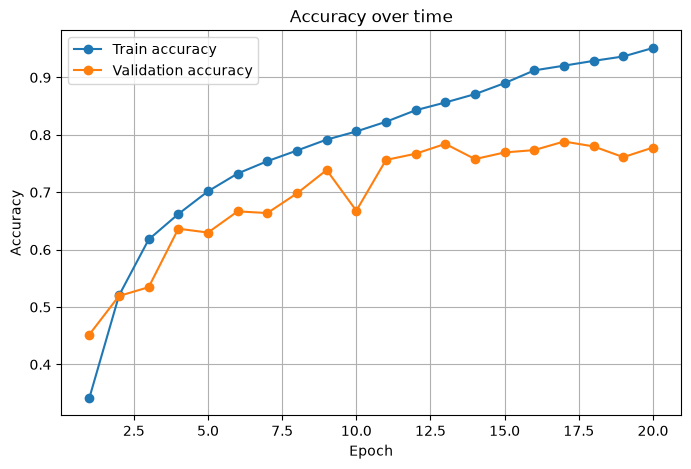

In [12]:
# ---------------------------------------------------------------------------
# 6. PLOT ACCURACY OVER TIME
# ---------------------------------------------------------------------------
# `train_accuracies` and `val_accuracies` were filled in with one value per
# epoch inside the training loop above. Plotting both on the same axes
# makes it easy to see the model improving over time, and to spot
# overfitting (train accuracy climbing while val accuracy flattens/drops).
import matplotlib.pyplot as plt
 
epochs_range = range(1, EPOCHS + 1)
 
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, train_accuracies, marker="o", label="Train accuracy")
plt.plot(epochs_range, val_accuracies, marker="o", label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy over time")
plt.legend()
plt.grid(True)
 
plot_path = "./accuracy_over_time.png"
plt.savefig(plot_path)
print(f"Accuracy plot saved to {plot_path}")
 
# `plt.show()` opens an interactive window if you're running this in an
# environment with a display (e.g. locally, not over SSH with no X server).
# It's harmless to leave in even if there's no display — some backends
# just no-op in that case — but comment it out if it ever hangs your run.
plt.show()
 

Sample training images saved to ./sample_training_images.png


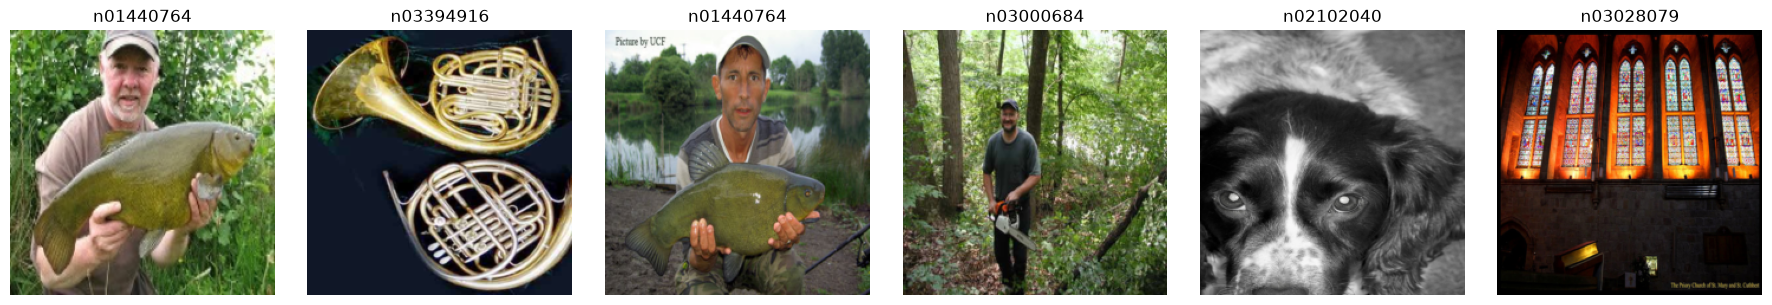

In [13]:
# ---------------------------------------------------------------------------
# 7. DISPLAY A FEW RANDOM TRAINING IMAGES WITH THEIR LABELS
# ---------------------------------------------------------------------------
# Purely a sanity check — lets you eyeball that images and labels are being
# read from the CSV correctly. We pull straight from `train_data`, so each
# image comes back already resized + normalized by `transform`.
NUM_SAMPLES_TO_SHOW = 6
sample_indices = random.sample(range(len(train_data)), NUM_SAMPLES_TO_SHOW)
 
fig, axes = plt.subplots(1, NUM_SAMPLES_TO_SHOW, figsize=(3 * NUM_SAMPLES_TO_SHOW, 3))
 
mean_tensor = torch.tensor(MEAN).view(3, 1, 1)
std_tensor = torch.tensor(STD).view(3, 1, 1)
 
for ax, idx in zip(axes, sample_indices):
    image_tensor, label_index = train_data[idx]
 
    # The transform normalized pixel values earlier (subtract mean, divide
    # by std) so the model trains well — but that also makes the image look
    # washed-out/wrong if plotted directly. Undo that here purely for
    # display: multiply back by std and add back the mean.
    unnormalized = image_tensor * std_tensor + mean_tensor
    unnormalized = unnormalized.clamp(0, 1)  # keep valid pixel range after undoing normalization
 
    # matplotlib expects images as (height, width, channels), but PyTorch
    # tensors are (channels, height, width) — permute reorders the axes.
    image_for_display = unnormalized.permute(1, 2, 0).numpy()
 
    ax.imshow(image_for_display)
    ax.set_title(class_names[label_index])
    ax.axis("off")
 
plt.tight_layout()
 
sample_plot_path = "./sample_training_images.png"
plt.savefig(sample_plot_path)
print(f"Sample training images saved to {sample_plot_path}")
 
plt.show()
 

In [14]:
# ---------------------------------------------------------------------------
# 8. MAXIMUM VALIDATION ACCURACY OVER THE FIRST 15 EPOCHS
# ---------------------------------------------------------------------------
# `val_accuracies` holds one value per epoch (index 0 = epoch 1), recorded in the
# training loop. Note that "validation" now means the MI-FGSM adversarial images.
# Slicing with [:15] keeps only epochs 1-15; if fewer than 15 epochs were run,
# the slice simply uses however many exist.
N_EPOCHS_TO_CHECK = 15

first_n = val_accuracies[:N_EPOCHS_TO_CHECK]
max_val_acc = max(first_n)
best_epoch = first_n.index(max_val_acc) + 1     # +1 because epochs are numbered from 1

print(f"Maximum validation accuracy over the first {len(first_n)} epochs: "
      f"{max_val_acc:.4f} ({max_val_acc * 100:.2f}%) at epoch {best_epoch}")

Maximum validation accuracy over the first 15 epochs: 0.7842 (78.42%) at epoch 13
